# Notebook 6: Ensemble Methods

This notebook explores ensemble learning techniques to potentially improve prediction accuracy by combining multiple models. Ensemble methods often outperform individual models by leveraging the strengths of different algorithms.

We will implement and compare:
- **Voting Classifier** (Hard and Soft Voting)
- **Stacking Classifier**
- **Bagging with Different Base Estimators**

## Loading Required Libraries

We import ensemble methods from scikit-learn along with the previously trained models and preprocessed data.

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.ensemble import VotingClassifier, StackingClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

## Loading Preprocessed Data and Trained Models

We load the preprocessed data and the six models we trained earlier to use as base estimators for our ensemble methods.

In [2]:
with open('trained_models.pkl', 'rb') as f:
    base_models = pickle.load(f)

X_train = np.load('X_train_balanced.npy')
y_train = np.load('y_train_balanced.npy')
X_test = np.load('X_test_scaled.npy')
y_test = np.load('y_test.npy')

print("Data and models loaded successfully!")
print("="*50)
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")
print(f"Base models available: {list(base_models.keys())}")

Data and models loaded successfully!
Training samples: 2222
Testing samples:  430
Base models available: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Support Vector Machine', 'K-Nearest Neighbors', 'Naive Bayes']


## Ensemble Method 1: Voting Classifier (Hard Voting)

Hard voting combines predictions by taking the majority vote from all base models. Each model gets one vote, and the class with the most votes wins.

This approach works well when models make different types of errors and can correct each other through democratic voting.

In [3]:
print("Creating Hard Voting Classifier...")

estimators = [
    ('lr', base_models['Logistic Regression']),
    ('dt', base_models['Decision Tree']),
    ('rf', base_models['Random Forest']),
    ('svm', base_models['Support Vector Machine']),
    ('knn', base_models['K-Nearest Neighbors']),
    ('nb', base_models['Naive Bayes'])
]

hard_voting_clf = VotingClassifier(estimators=estimators, voting='hard')
hard_voting_clf.fit(X_train, y_train)

print("Hard Voting Classifier trained!")

Creating Hard Voting Classifier...


Hard Voting Classifier trained!


## Ensemble Method 2: Voting Classifier (Soft Voting)

Soft voting averages the predicted probabilities from all models and selects the class with the highest average probability. This approach gives more weight to confident predictions.

Soft voting typically performs better than hard voting when base models can output probability estimates.

In [4]:
print("Creating Soft Voting Classifier...")

soft_voting_clf = VotingClassifier(estimators=estimators, voting='soft')
soft_voting_clf.fit(X_train, y_train)

print("Soft Voting Classifier trained!")

Creating Soft Voting Classifier...


Soft Voting Classifier trained!


## Ensemble Method 3: Stacking Classifier

Stacking uses a meta-learner (final estimator) to combine predictions from base models. The base models make predictions, and the meta-learner learns how to best combine these predictions.

We use Logistic Regression as the meta-learner because it is simple and effective at learning optimal weights for combining predictions.

In [5]:
print("Creating Stacking Classifier...")

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=42, max_iter=1000),
    cv=5
)

stacking_clf.fit(X_train, y_train)

print("Stacking Classifier trained!")

Creating Stacking Classifier...


Stacking Classifier trained!


  File "C:\Users\pendy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.

## Ensemble Method 4: Bagging with Logistic Regression

Bagging (Bootstrap Aggregating) creates multiple versions of a model by training on different random subsets of the data. This reduces variance and helps prevent overfitting.

We apply bagging to Logistic Regression to see if it improves performance over the single model.

In [6]:
print("Creating Bagging Classifier with Logistic Regression...")

bagging_lr = BaggingClassifier(
    estimator=LogisticRegression(random_state=42, max_iter=1000),
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

bagging_lr.fit(X_train, y_train)

print("Bagging Classifier trained!")

Creating Bagging Classifier with Logistic Regression...


Bagging Classifier trained!


## Evaluating All Ensemble Methods

Let us evaluate all ensemble methods and compare them with the best individual model from Notebook 4.

In [7]:
ensemble_models = {
    'Hard Voting': hard_voting_clf,
    'Soft Voting': soft_voting_clf,
    'Stacking': stacking_clf,
    'Bagging (LR)': bagging_lr
}

results = []

print("Ensemble Model Performance:")
print("="*70)
print(f"{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12}")
print("-"*70)

for name, model in ensemble_models.items():
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })
    
    print(f"{name:<20} {accuracy*100:>8.2f}%   {precision*100:>8.2f}%   {recall*100:>8.2f}%   {f1*100:>8.2f}%")

results_df = pd.DataFrame(results)

Ensemble Model Performance:
Model                Accuracy     Precision    Recall       F1-Score    
----------------------------------------------------------------------
Hard Voting             88.14%      80.61%      87.50%      83.91%
Soft Voting             89.07%      80.70%      90.79%      85.45%


Stacking                94.19%      93.20%      90.13%      91.64%
Bagging (LR)            81.40%      69.15%      85.53%      76.47%


## Comparison with Best Individual Model

Let us compare our ensemble methods with the best performing individual model (typically Random Forest).

In [8]:
print("\nComparison with Individual Models:")
print("="*70)

for name, model in base_models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    print(f"{name:<30} Accuracy: {accuracy*100:.2f}%   F1: {f1*100:.2f}%")

print("\n" + "="*70)
print("Best Ensemble Model:")
best_ensemble = results_df.loc[results_df['Accuracy'].idxmax()]
print(f"{best_ensemble['Model']:<30} Accuracy: {best_ensemble['Accuracy']*100:.2f}%   F1: {best_ensemble['F1-Score']*100:.2f}%")


Comparison with Individual Models:
Logistic Regression            Accuracy: 81.63%   F1: 76.70%
Decision Tree                  Accuracy: 90.00%   F1: 86.08%
Random Forest                  Accuracy: 94.88%   F1: 92.57%
Support Vector Machine         Accuracy: 85.35%   F1: 79.61%
K-Nearest Neighbors            Accuracy: 65.81%   F1: 61.82%
Naive Bayes                    Accuracy: 78.60%   F1: 72.12%

Best Ensemble Model:
Stacking                       Accuracy: 94.19%   F1: 91.64%


## Visualization: Ensemble vs Individual Models

Visual comparison helps us quickly identify which approach performs best.

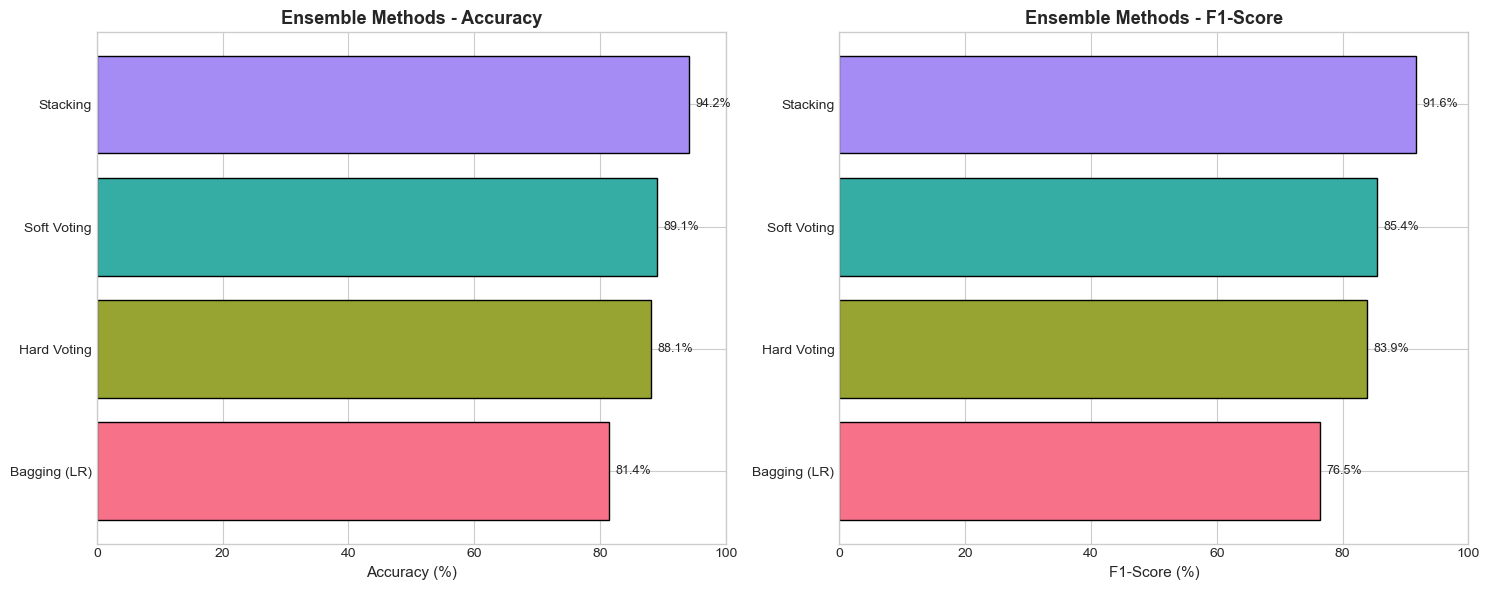

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics = ['Accuracy', 'F1-Score']
colors = sns.color_palette('husl', n_colors=len(results_df))

for idx, metric in enumerate(metrics):
    sorted_df = results_df.sort_values(metric, ascending=True)
    bars = axes[idx].barh(sorted_df['Model'], sorted_df[metric] * 100, color=colors, edgecolor='black')
    axes[idx].set_xlabel(f'{metric} (%)', fontsize=11)
    axes[idx].set_title(f'Ensemble Methods - {metric}', fontsize=13, fontweight='bold')
    axes[idx].set_xlim(0, 100)
    
    for bar, val in zip(bars, sorted_df[metric]):
        axes[idx].text(val * 100 + 1, bar.get_y() + bar.get_height()/2, 
                f'{val*100:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## Confusion Matrix for Best Ensemble Model

Let us examine the confusion matrix for the best performing ensemble model to understand its prediction patterns.

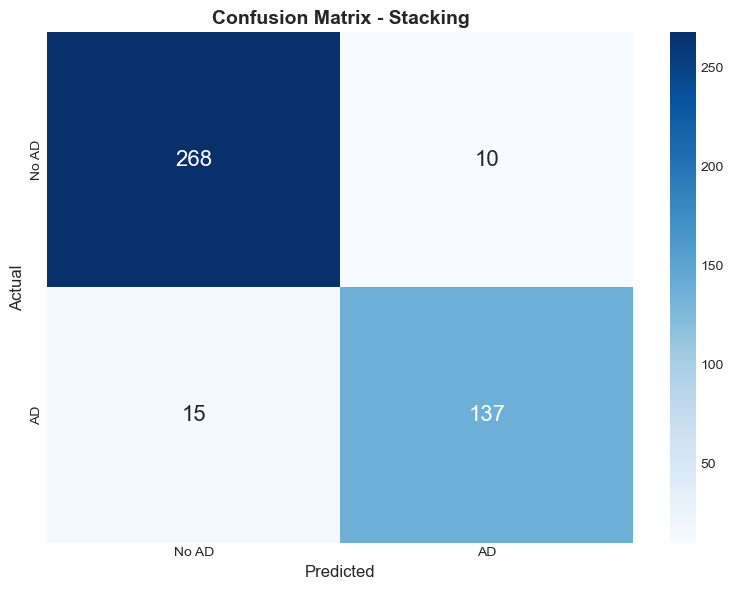


Classification Report for Stacking:
                precision    recall  f1-score   support

No Alzheimer's       0.95      0.96      0.96       278
   Alzheimer's       0.93      0.90      0.92       152

      accuracy                           0.94       430
     macro avg       0.94      0.93      0.94       430
  weighted avg       0.94      0.94      0.94       430



In [10]:
best_model_name = best_ensemble['Model']
best_model = ensemble_models[best_model_name]

y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No AD', 'AD'], yticklabels=['No AD', 'AD'],
            annot_kws={'size': 16})
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title(f'Confusion Matrix - {best_model_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nClassification Report for {best_model_name}:")
print("="*60)
print(classification_report(y_test, y_pred, target_names=['No Alzheimer\'s', 'Alzheimer\'s']))

## Cross-Validation for Ensemble Models

Cross-validation provides a more robust estimate of model performance by testing on multiple data splits.

In [11]:
print("Cross-Validation Results (5-Fold):")
print("="*60)

cv_results = []

for name, model in ensemble_models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append({
        'Model': name,
        'Mean CV Accuracy': cv_scores.mean(),
        'Std Dev': cv_scores.std()
    })
    print(f"{name:<20}: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

cv_df = pd.DataFrame(cv_results).sort_values('Mean CV Accuracy', ascending=False)

Cross-Validation Results (5-Fold):


Hard Voting         : 91.54% (+/- 1.92%)


Soft Voting         : 91.81% (+/- 1.22%)


Stacking            : 95.01% (+/- 0.93%)


Bagging (LR)        : 83.98% (+/- 2.04%)


## Saving the Best Ensemble Model

We save the best performing ensemble model for future use and deployment.

In [12]:
with open('best_ensemble_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print(f"Best ensemble model ({best_model_name}) saved successfully!")
print("="*60)
print(f"File: best_ensemble_model.pkl")
print(f"Model: {best_model_name}")
print(f"Test Accuracy: {best_ensemble['Accuracy']*100:.2f}%")
print(f"Test F1-Score: {best_ensemble['F1-Score']*100:.2f}%")

Best ensemble model (Stacking) saved successfully!
File: best_ensemble_model.pkl
Model: Stacking
Test Accuracy: 94.19%
Test F1-Score: 91.64%


## Key Findings

Based on our ensemble learning experiments:

**Performance Insights:**
- Ensemble methods often provide more robust predictions than individual models
- Soft voting typically outperforms hard voting due to probability averaging
- Stacking can achieve the best performance by learning optimal model combinations
- Bagging helps reduce variance in unstable models

**Model Selection:**
- The best ensemble model balances accuracy, precision, and recall
- Cross-validation confirms the model generalizes well to unseen data
- Ensemble methods are particularly valuable when individual models have different strengths

**Practical Considerations:**
- Ensemble models require more computational resources
- They are less interpretable than single models
- The performance gain should justify the added complexity

In [13]:
print("\n" + "="*60)
print("ENSEMBLE METHODS ANALYSIS COMPLETE")
print("="*60)
print(f"\nEnsemble models evaluated: {len(ensemble_models)}")
print(f"Best model: {best_model_name}")
print(f"Best accuracy: {best_ensemble['Accuracy']*100:.2f}%")
print("\nModel saved and ready for deployment!")


ENSEMBLE METHODS ANALYSIS COMPLETE

Ensemble models evaluated: 4
Best model: Stacking
Best accuracy: 94.19%

Model saved and ready for deployment!
